Features: liquidity, market state, normalization, model table

Day 4. Adds liquidity features and market-state variables, rank-normalizes everything within each month,
builds the final model table and runs automated checks.
Inputs: `panel.csv`, `labels.csv`, `features_raw.csv`.
Outputs: `features_raw_day4.csv` and `model_table.csv`.

## Setup

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# src is one folder up from notebooks, so add that folder so the import works
sys.path.append("..")
from src.data import load_data
from src.features import make_wide, make_market_return, make_liquidity_features
from src.features import make_state_variables, wide_dict_to_long, build_all_features
from src.normalize import rank_normalize, sector_relative

PANEL_PATH = "../data/processed/panel.csv"
LABELS_PATH = "../data/processed/labels.csv"
FEATURES_RAW_PATH = "../data/processed/features_raw.csv"
DAY4_RAW_PATH = "../data/processed/features_raw_day4.csv"
MODEL_TABLE_PATH = "../data/processed/model_table.csv"

## Load inputs

In [2]:
panel = load_data(PANEL_PATH)
labels = pd.read_csv(LABELS_PATH, parse_dates=["Date"])
features_raw = pd.read_csv(FEATURES_RAW_PATH, parse_dates=["Date"])

# decision dates come from labels so everything shares one grid
decision_dates = pd.DatetimeIndex(sorted(labels["Date"].unique()), name="Date")

print("panel shape:", panel.shape)
print("labels shape:", labels.shape)
print("day 3 features shape:", features_raw.shape)
print("number of decision dates:", len(decision_dates))

panel shape: (57300, 17)
labels shape: (2760, 6)
day 3 features shape: (2760, 11)
number of decision dates: 92


## Part A: liquidity features

In [3]:
turnover_wide = make_wide(panel, "Turnover")
daily_returns_wide = make_wide(panel, "Daily_Return")
market_return = make_market_return(daily_returns_wide)

liquidity_features = make_liquidity_features(turnover_wide, daily_returns_wide, decision_dates)
liquidity_names = list(liquidity_features.keys())

# show the four liquidity features side by side for one ticker
example_ticker = "INFY.NS"
example_liquidity = pd.DataFrame()
for name in liquidity_names:
    example_liquidity[name] = liquidity_features[name][example_ticker]

print("liquidity features for", example_ticker)
print(example_liquidity.iloc[10:16])

liquidity features for INFY.NS
            log_turnover_21d  turnover_cv_21d  abn_turnover  amihud_21d
Date                                                                   
2019-11-29         22.843949         0.655385           NaN    0.001610
2019-12-31         22.299450         0.390559           NaN    0.001623
2020-01-31         22.608847         0.830615      0.999596    0.001599
2020-02-28         22.196330         0.421179      0.664813    0.002378
2020-03-31         22.932158         0.204681      1.326955    0.004451
2020-04-30         22.747875         0.282007      1.099641    0.003480


In [4]:
# one row per (Date, Ticker)
liquidity_long = wide_dict_to_long(liquidity_features)

print("liquidity table shape:", liquidity_long.shape)
print()
print("summary of the four liquidity features:")
print(liquidity_long[liquidity_names].describe().round(4))

liquidity table shape: (2760, 6)

summary of the four liquidity features:
       log_turnover_21d  turnover_cv_21d  abn_turnover  amihud_21d
count         2760.0000        2760.0000     2400.0000   2669.0000
mean            21.6897           0.5713        1.0750      0.0131
std              1.0055           0.2760        0.4260      0.0438
min             17.3098           0.1517        0.3582      0.0003
25%             21.0461           0.3964        0.8080      0.0023
50%             21.7030           0.5014        0.9962      0.0050
75%             22.4018           0.6615        1.2487      0.0102
max             24.1794           3.0278        5.5187      0.6769


In [5]:
# put day 3 and day 4 stock features side by side
stock_features_raw = pd.merge(features_raw, liquidity_long, on=["Date", "Ticker"], validate="one_to_one")
stock_feature_names = [c for c in stock_features_raw.columns if c not in ["Date", "Ticker"]]

print("stock features shape:", stock_features_raw.shape)
print("number of stock features:", len(stock_feature_names))
print(stock_feature_names)

stock features shape: (2760, 15)
number of stock features: 13
['mom_1m', 'mom_6_1', 'mom_12_1', 'chmom', 'retvol_21d', 'retvol_63d', 'maxret_21d', 'beta_252d', 'idiovol_252d', 'log_turnover_21d', 'turnover_cv_21d', 'abn_turnover', 'amihud_21d']


## Part B: market-state variables

In [6]:
# xs_dispersion needs every stock's mom_1m, so make it wide again (rows = decision dates)
mom_1m_wide = features_raw.pivot(index="Date", columns="Ticker", values="mom_1m")

state_variables = make_state_variables(market_return, mom_1m_wide, decision_dates)
state_names = list(state_variables.columns)
raw_state_names = [name for name in state_names if not name.endswith("_z")]

print("state variables shape (dates, variables):", state_variables.shape)
print()
print(state_variables.iloc[10:16].round(4))
print()
for name in state_names:
    print(name, "first valid date:", state_variables[name].first_valid_index().date())

state variables shape (dates, variables): (92, 8)

            mkt_ret_1m  mkt_ret_12m  mkt_vol_63d  xs_dispersion  mkt_ret_1m_z  \
Date                                                                            
2019-11-29     -0.0079          NaN       0.0115         0.0599           NaN   
2019-12-31      0.0091          NaN       0.0075         0.0411           NaN   
2020-01-31      0.0084       0.0696       0.0071         0.0818        0.0962   
2020-02-28     -0.0719      -0.0002       0.0097         0.0648       -2.1934   
2020-03-31     -0.2283      -0.2569       0.0270         0.1547       -3.0879   
2020-04-30      0.1755      -0.1492       0.0310         0.1387        2.1675   

            mkt_ret_12m_z  mkt_vol_63d_z  xs_dispersion_z  
Date                                                       
2019-11-29            NaN            NaN              NaN  
2019-12-31            NaN            NaN              NaN  
2020-01-31            NaN            NaN           0.7838  


## Part C: normalization

In [7]:
# each ticker should have exactly one sector
sector_table = panel[["Ticker", "Sector"]].drop_duplicates()
print("tickers with more than one sector:", sector_table["Ticker"].duplicated().sum())

stocks_per_sector = sector_table.groupby("Sector").size().sort_values()
print()
print("stocks per sector:")
print(stocks_per_sector)

small_sectors = stocks_per_sector[stocks_per_sector < 3]
print()
print("sectors with fewer than 3 stocks:", len(small_sectors))
print("stocks in those sectors (sector-relative will be nan, then 0):", small_sectors.sum(), "out of", len(sector_table))

tickers with more than one sector: 0

stocks per sector:
Sector
Auto Components           1
Consumer Durables         1
Consumer                  1
Chemicals                 1
Metals                    1
Mining                    1
Oil & Gas                 1
Engineering               1
Cement                    2
Capital Goods             2
FMCG                      3
Automobile                3
Banking                   4
Healthcare                4
Information Technology    4
dtype: int64

sectors with fewer than 3 stocks: 10
stocks in those sectors (sector-relative will be nan, then 0): 12 out of 30


In [8]:
# add sector, then rank-normalize every stock feature within each date
stock_table = pd.merge(stock_features_raw, sector_table, on="Ticker", validate="many_to_one")
stock_table = rank_normalize(stock_table, stock_feature_names)

n_columns = [name + "_n" for name in stock_feature_names]

print("min / max / mean of the normalized columns:")
print(stock_table[n_columns].describe().loc[["min", "max", "mean"]].round(3))

min / max / mean of the normalized columns:
      mom_1m_n  mom_6_1_n  mom_12_1_n  chmom_n  retvol_21d_n  retvol_63d_n  \
min       -1.0       -1.0        -1.0     -1.0          -1.0          -1.0   
max        1.0        1.0         1.0      1.0           1.0           1.0   
mean       0.0        0.0         0.0      0.0           0.0           0.0   

      maxret_21d_n  beta_252d_n  idiovol_252d_n  log_turnover_21d_n  \
min           -1.0         -1.0            -1.0                -1.0   
max            1.0          1.0             1.0                 1.0   
mean           0.0          0.0             0.0                 0.0   

      turnover_cv_21d_n  abn_turnover_n  amihud_21d_n  
min                -1.0            -1.0          -1.0  
max                 1.0             1.0           1.0  
mean               -0.0             0.0           0.0  


In [9]:
# sector-relative versions for 4 features
secrel_features = ["mom_12_1", "retvol_63d", "abn_turnover", "amihud_21d"]
secrel_columns = [name + "_secrel" for name in secrel_features]

stock_table = sector_relative(stock_table, secrel_features, min_stocks=3)

# look at one month so the idea is visible
example_date = pd.Timestamp("2023-06-30")
example_rows = stock_table[stock_table["Date"] == example_date]
example_rows = example_rows.sort_values(["Sector", "Ticker"])
print("example month:", example_date.date())
print(example_rows[["Ticker", "Sector", "mom_12_1", "mom_12_1_n", "mom_12_1_secrel"]].round(3).to_string(index=False))

example month: 2023-06-30
       Ticker                 Sector  mom_12_1  mom_12_1_n  mom_12_1_secrel
BHARATFORG.NS        Auto Components     0.227       0.034            0.000
  ASHOKLEY.NS             Automobile    -0.003      -0.862           -0.765
       M&M.NS             Automobile     0.219      -0.034            0.882
    MARUTI.NS             Automobile     0.113      -0.655            0.000
  AXISBANK.NS                Banking     0.439       0.931            0.412
FEDERALBNK.NS                Banking     0.413       0.724            0.176
 ICICIBANK.NS                Banking     0.350       0.586           -0.294
      SBIN.NS                Banking     0.269       0.241           -0.647
CUMMINSIND.NS          Capital Goods     0.746       1.000            0.000
   THERMAX.NS          Capital Goods     0.118      -0.586            0.000
  SHREECEM.NS                 Cement     0.329       0.517            0.000
ULTRACEMCO.NS                 Cement     0.412       0.655    

## Part D: model table

In [10]:
# stock features (normalized) + sector
model_table = stock_table[["Date", "Ticker", "Sector"] + n_columns + secrel_columns]

# state variables are the same for every stock on a date, so merge on Date only
state_long = state_variables.reset_index()
model_table = pd.merge(model_table, state_long, on="Date", how="left", validate="many_to_one")

# labels, keep rows even when the label is missing
label_columns = ["fwd_1m", "fwd_3m", "fwd_6m", "fwd_1m_rank"]
model_table = pd.merge(model_table, labels[["Date", "Ticker"] + label_columns],
                       on=["Date", "Ticker"], how="left", validate="one_to_one")
model_table["has_label_1m"] = model_table["fwd_1m"].notna()

# chronological split from the year
year = model_table["Date"].dt.year
model_table["split"] = "test"
model_table.loc[year == 2019, "split"] = "warmup"
model_table.loc[(year >= 2020) & (year <= 2023), "split"] = "train"
model_table.loc[year == 2024, "split"] = "validation"

model_table = model_table.sort_values(["Ticker", "Date"])
model_table = model_table.reset_index(drop=True)

print("model table shape:", model_table.shape)
print()
print("columns:")
print(list(model_table.columns))

model table shape:

 (2760, 34)

columns:
['Date', 'Ticker', 'Sector', 'mom_1m_n', 'mom_6_1_n', 'mom_12_1_n', 'chmom_n', 'retvol_21d_n', 'retvol_63d_n', 'maxret_21d_n', 'beta_252d_n', 'idiovol_252d_n', 'log_turnover_21d_n', 'turnover_cv_21d_n', 'abn_turnover_n', 'amihud_21d_n', 'mom_12_1_secrel', 'retvol_63d_secrel', 'abn_turnover_secrel', 'amihud_21d_secrel', 'mkt_ret_1m', 'mkt_ret_12m', 'mkt_vol_63d', 'xs_dispersion', 'mkt_ret_1m_z', 'mkt_ret_12m_z', 'mkt_vol_63d_z', 'xs_dispersion_z', 'fwd_1m', 'fwd_3m', 'fwd_6m', 'fwd_1m_rank', 'has_label_1m', 'split']


In [11]:
model_table.to_csv(MODEL_TABLE_PATH, index=False)

# un-normalized day 4 features: the 4 liquidity features per stock + the state variables per date
day4_raw = pd.merge(liquidity_long, state_long, on="Date", how="left", validate="many_to_one")
day4_raw.to_csv(DAY4_RAW_PATH, index=False)

print("saved", MODEL_TABLE_PATH, "rows:", len(model_table))
print("saved", DAY4_RAW_PATH, "rows:", len(day4_raw), "columns:", list(day4_raw.columns))

saved

 ../data/processed/model_table.csv rows: 2760
saved ../data/processed/features_raw_day4.csv rows: 2760 columns: ['Date', 'Ticker', 'log_turnover_21d', 'turnover_cv_21d', 'abn_turnover', 'amihud_21d', 'mkt_ret_1m', 'mkt_ret_12m', 'mkt_vol_63d', 'xs_dispersion', 'mkt_ret_1m_z', 'mkt_ret_12m_z', 'mkt_vol_63d_z', 'xs_dispersion_z']


In [12]:
# the checks below run on the files as saved on disk, not on the in-memory tables
saved_model_table = pd.read_csv(MODEL_TABLE_PATH, parse_dates=["Date"])

print("reloaded shape:", saved_model_table.shape)
print("same shape as in memory:", saved_model_table.shape == model_table.shape)
print("has_label_1m dtype:", saved_model_table["has_label_1m"].dtype)

reloaded shape: (2760, 34)
same shape as in memory: True
has_label_1m dtype: bool


## Part E: automated checks

In [13]:
# every check prints PASS or FAIL and stores the result for the summary at the end
check_results = {}

def report_check(name, passed):
    check_results[name] = passed
    if passed:
        print("PASS:", name)
    else:
        print("FAIL:", name)

### Check 1: leakage test (rebuild every feature on changed panels)

Two versions of the changed panel, both only change rows **after** 2023-06-30:
1. uniform: Adj_Close and Turnover x 1.5 on every later day (the version asked for).
2. uneven: x 1.5 only on even calendar days. Needed because a ratio like std/mean (`turnover_cv_21d`) does not change when everything is scaled by the same amount, so version 1 alone cannot test it.

In [14]:
cutoff_date = pd.Timestamp("2023-06-30")

def make_changed_panel(panel, cutoff_date, only_even_days):
    # copy so the real panel is never touched
    changed_panel = panel.copy()

    # rows after the cutoff get changed
    change_rows = changed_panel["Date"] > cutoff_date
    if only_even_days:
        # second version: only even calendar days, so the change is uneven over time
        change_rows = change_rows & (changed_panel["Date"].dt.day % 2 == 0)

    changed_panel.loc[change_rows, "Adj_Close"] = changed_panel.loc[change_rows, "Adj_Close"] * 1.5
    changed_panel.loc[change_rows, "Turnover"] = changed_panel.loc[change_rows, "Turnover"] * 1.5

    # returns must be recomputed from the changed prices, otherwise the old Daily_Return column hides the change
    changed_panel["Daily_Return"] = changed_panel.groupby("Ticker")["Adj_Close"].pct_change()
    return changed_panel, change_rows.sum()

# baseline: returns recomputed from Adj_Close the same way
panel_base = panel.copy()
panel_base["Daily_Return"] = panel_base.groupby("Ticker")["Adj_Close"].pct_change()

panel_uniform, rows_changed_uniform = make_changed_panel(panel, cutoff_date, False)
panel_uneven, rows_changed_uneven = make_changed_panel(panel, cutoff_date, True)
print("rows changed (uniform):", rows_changed_uniform, "| rows changed (uneven):", rows_changed_uneven, "| total rows:", len(panel))

# rebuild all features (day 3 + day 4 + state variables) on all three panels
base_stock, base_state = build_all_features(panel_base, decision_dates)
uniform_stock, uniform_state = build_all_features(panel_uniform, decision_dates)
uneven_stock, uneven_state = build_all_features(panel_uneven, decision_dates)

print("features shape:", base_stock.shape, "| state shape:", base_state.shape)

rows changed (uniform): 23940 | rows changed (uneven): 11760 | total rows: 57300


features shape: (2760, 15) | state shape: (92, 8)


In [15]:
def compare_to_base(changed_stock, changed_state, label):
    unchanged_before = {}
    changed_after = {}

    stock_before = base_stock["Date"] <= cutoff_date
    for name in stock_feature_names:
        unchanged_before[name] = np.allclose(base_stock.loc[stock_before, name], changed_stock.loc[stock_before, name],
                                             rtol=1e-9, atol=1e-12, equal_nan=True)
        same_after = np.allclose(base_stock.loc[~stock_before, name], changed_stock.loc[~stock_before, name],
                                 rtol=1e-9, atol=1e-12, equal_nan=True)
        changed_after[name] = not same_after

    # state variables sit in a table indexed by date
    state_before = base_state.index <= cutoff_date
    for name in state_names:
        unchanged_before[name] = np.allclose(base_state.loc[state_before, name], changed_state.loc[state_before, name],
                                             rtol=1e-9, atol=1e-12, equal_nan=True)
        same_after = np.allclose(base_state.loc[~state_before, name], changed_state.loc[~state_before, name],
                                 rtol=1e-9, atol=1e-12, equal_nan=True)
        changed_after[name] = not same_after

    print(label)
    for name in unchanged_before:
        print("  ", name, "| unchanged on dates <= cutoff:", unchanged_before[name], "| changed after cutoff:", changed_after[name])
    print()
    return unchanged_before, changed_after

rows_line_up = base_stock[["Date", "Ticker"]].equals(uniform_stock[["Date", "Ticker"]]) and base_stock[["Date", "Ticker"]].equals(uneven_stock[["Date", "Ticker"]])
print("rows line up between base and changed tables:", rows_line_up)
print()

uniform_unchanged, uniform_changed_after = compare_to_base(uniform_stock, uniform_state, "test 1: uniform x1.5 after cutoff")
uneven_unchanged, uneven_changed_after = compare_to_base(uneven_stock, uneven_state, "test 2: x1.5 on even days after cutoff")

rows line up between base and changed tables: True

test 1: uniform x1.5 after cutoff
   mom_1m | unchanged on dates <= cutoff: True | changed after cutoff: True
   mom_6_1 | unchanged on dates <= cutoff: True | changed after cutoff: True
   mom_12_1 | unchanged on dates <= cutoff: True | changed after cutoff: True
   chmom | unchanged on dates <= cutoff: True | changed after cutoff: True
   retvol_21d | unchanged on dates <= cutoff: True | changed after cutoff: True
   retvol_63d | unchanged on dates <= cutoff: True | changed after cutoff: True
   maxret_21d | unchanged on dates <= cutoff: True | changed after cutoff: True
   beta_252d | unchanged on dates <= cutoff: True | changed after cutoff: True
   idiovol_252d | unchanged on dates <= cutoff: True | changed after cutoff: True
   log_turnover_21d | unchanged on dates <= cutoff: True | changed after cutoff: True
   turnover_cv_21d | unchanged on dates <= cutoff: True | changed after cutoff: False
   abn_turnover | unchanged on date

In [16]:
# turn the dictionaries above into PASS / FAIL lines
leaking_uniform = []
leaking_uneven = []
not_sensitive = []

for name in uniform_unchanged:
    if not uniform_unchanged[name]:
        leaking_uniform.append(name)
    if not uneven_unchanged[name]:
        leaking_uneven.append(name)
    # sensitive means the feature changed after the cutoff in at least one of the two tests
    if not (uniform_changed_after[name] or uneven_changed_after[name]):
        not_sensitive.append(name)

report_check("1. leakage test (uniform x1.5): all features on dates <= 2023-06-30 unchanged", rows_line_up and len(leaking_uniform) == 0)
report_check("1b. leakage test (x1.5 on even days): all features on dates <= 2023-06-30 unchanged", len(leaking_uneven) == 0)
report_check("1c. the two tests together are sensitive: every feature changes after the cutoff", len(not_sensitive) == 0)
print("leaking in test 1:", leaking_uniform, "| leaking in test 2:", leaking_uneven, "| not sensitive:", not_sensitive)

PASS: 1. leakage test (uniform x1.5): all features on dates <= 2023-06-30 unchanged
PASS: 1b. leakage test (x1.5 on even days): all features on dates <= 2023-06-30 unchanged
PASS: 1c. the two tests together are sensitive: every feature changes after the cutoff
leaking in test 1: [] | leaking in test 2: [] | not sensitive: []


In [17]:
# check 1d: the rebuilt day 3 + day 4 features match the ones used for the model table
# (base panel uses recomputed returns, so allow a tiny tolerance)
rebuild_matches = True
for name in stock_feature_names:
    close_enough = np.allclose(base_stock[name], stock_features_raw[name], rtol=1e-6, atol=1e-9, equal_nan=True)
    if not close_enough:
        rebuild_matches = False
        print("mismatch in", name)

report_check("1d. rebuilt features match the features used in the model table", rebuild_matches)

PASS: 1d. rebuilt features match the features used in the model table


### Check 2: normalized columns are inside [-1, 1] with no nans

In [18]:
bad_columns = []
for column in n_columns + secrel_columns:
    values = saved_model_table[column]
    inside_range = values.between(-1, 1).all()
    no_nans = values.notna().all()
    if not (inside_range and no_nans):
        bad_columns.append(column)

print("columns checked:", len(n_columns + secrel_columns))
print("overall min:", saved_model_table[n_columns + secrel_columns].min().min())
print("overall max:", saved_model_table[n_columns + secrel_columns].max().max())
report_check("2. all _n and _secrel columns within [-1, 1], no nans", len(bad_columns) == 0)
if len(bad_columns) > 0:
    print("bad columns:", bad_columns)

columns checked: 17
overall min: -1.0
overall max: 1.0
PASS: 2. all _n and _secrel columns within [-1, 1], no nans


### Check 3: 30 rows per date

In [19]:
rows_per_date = saved_model_table.groupby("Date").size()

print("number of dates:", len(rows_per_date))
print("min rows per date:", rows_per_date.min(), " max rows per date:", rows_per_date.max())
report_check("3. every date has exactly 30 rows", (rows_per_date == 30).all() and len(rows_per_date) == len(decision_dates))

number of dates: 92
min rows per date: 30  max rows per date: 30
PASS: 3. every date has exactly 30 rows


### Check 4: state variables are constant within a date

In [20]:
# nunique with dropna=False counts nan as a value, so an all-nan date counts as 1 unique value
unique_values_per_date = saved_model_table.groupby("Date")[state_names].nunique(dropna=False)

print("max unique values per date, per state variable:")
print(unique_values_per_date.max())
report_check("4. each state variable has one unique value per date", (unique_values_per_date == 1).all().all())

max unique values per date, per state variable:
mkt_ret_1m         1
mkt_ret_12m        1
mkt_vol_63d        1
xs_dispersion      1
mkt_ret_1m_z       1
mkt_ret_12m_z      1
mkt_vol_63d_z      1
xs_dispersion_z    1
dtype: int64
PASS: 4. each state variable has one unique value per date


### Check 5: _z state variables recomputed by hand

In [21]:
check_dates = [pd.Timestamp("2021-03-31"), pd.Timestamp("2023-06-30"), pd.Timestamp("2025-02-28")]
all_z_match = True

for check_date in check_dates:
    for name in raw_state_names:
        # only values up to and including check_date, no future values
        past_values = state_variables.loc[state_variables.index <= check_date, name].dropna().to_numpy()

        by_hand = (past_values[-1] - past_values.mean()) / past_values.std(ddof=1)
        from_table = saved_model_table.loc[saved_model_table["Date"] == check_date, name + "_z"].iloc[0]

        matches = abs(by_hand - from_table) < 1e-9 and len(past_values) >= 12
        if not matches:
            all_z_match = False
        print(check_date.date(), name, "| months used:", len(past_values),
              "| by hand:", round(by_hand, 5), "| table:", round(from_table, 5), "| match:", matches)

print()
report_check("5. _z state variables match a by-hand z-score on 3 dates", all_z_match)

2021-03-31 mkt_ret_1m | months used: 26 | by hand: 0.04097 | table: 0.04097 | match: True
2021-03-31 mkt_ret_12m | months used: 15 | by hand: 2.81927 | table: 2.81927 | match: True
2021-03-31 mkt_vol_63d | months used: 24 | by hand: 0.00412 | table: 0.00412 | match: True
2021-03-31 xs_dispersion | months used: 26 | by hand: -0.13414 | table: -0.13414 | match: True
2023-06-30 mkt_ret_1m | months used: 53 | by hand: 0.37623 | table: 0.37623 | match: True
2023-06-30 mkt_ret_12m | months used: 42 | by hand: 0.17176 | table: 0.17176 | match: True
2023-06-30 mkt_vol_63d | months used: 51 | by hand: -1.04039 | table: -1.04039 | match: True
2023-06-30 xs_dispersion | months used: 53 | by hand: -0.80686 | table: -0.80686 | match: True
2025-02-28 mkt_ret_1m | months used: 73 | by hand: -1.73902 | table: -1.73902 | match: True
2025-02-28 mkt_ret_12m | months used: 62 | by hand: -0.86077 | table: -0.86077 | match: True
2025-02-28 mkt_vol_63d | months used: 71 | by hand: -0.30308 | table: -0.30308 

### Check 6: split sanity

In [22]:
split_order = ["warmup", "train", "validation", "test"]
split_dates = {}

for split_name in split_order:
    rows = saved_model_table[saved_model_table["Date"].notna() & (saved_model_table["split"] == split_name)]
    split_dates[split_name] = set(rows["Date"].unique())
    print(split_name, "| rows:", len(rows), "| dates:", rows["Date"].nunique(),
          "| from", rows["Date"].min().date(), "to", rows["Date"].max().date())

# no date may sit in two splits
no_overlap = True
for i in range(len(split_order)):
    for j in range(i + 1, len(split_order)):
        shared = split_dates[split_order[i]] & split_dates[split_order[j]]
        if len(shared) > 0:
            no_overlap = False

# and the splits must follow each other in time
in_order = True
for i in range(len(split_order) - 1):
    if max(split_dates[split_order[i]]) >= min(split_dates[split_order[i + 1]]):
        in_order = False

total_rows = len(saved_model_table)
rows_in_splits = saved_model_table["split"].isin(split_order).sum()
print()
report_check("6. no date overlap between splits, splits in chronological order, every row has a split",
             no_overlap and in_order and rows_in_splits == total_rows)

warmup | rows: 360 | dates: 12 | from 2019-01-31 to 2019-12-31
train | rows: 1440 | dates: 48 | from 2020-01-31 to 2023-12-29
validation | rows: 360 | dates: 12 | from 2024-01-31 to 2024-12-31
test | rows: 600 | dates: 20 | from 2025-01-31 to 2026-08-31

PASS: 6. no date overlap between splits, splits in chronological order, every row has a split


### Check 7: nans per raw feature per year (before normalization)

In [23]:
raw_year = stock_features_raw["Date"].dt.year
nans_per_year = stock_features_raw[stock_feature_names].isna().groupby(raw_year).sum()

print("nan count per raw stock feature per year (30 stocks x 12 months = 360 rows per year):")
print(nans_per_year.T)

# train + validation years should be complete, warm-up is 2019
middle_years = nans_per_year.loc[2020:2024]
report_check("7. no nans in raw stock features during 2020-2024 (nans only in 2019 warm-up and test)",
             middle_years.sum().sum() == 0)

print()
print("nans left in the test period (2025+):")
late_nans = nans_per_year.loc[2025:].sum()
print(late_nans[late_nans > 0])

nan count per raw stock feature per year (30 stocks x 12 months = 360 rows per year):
Date              2019  2020  2021  2022  2023  2024  2025  2026
mom_1m              30     0     0     0     0     0     0     0
mom_6_1            180     0     0     0     0     0     0     0
mom_12_1           360     0     0     0     0     0     0     0
chmom              360     0     0     0     0     0     0     0
retvol_21d           0     0     0     0     0     0     0     0
retvol_63d          90     0     0     0     0     0     0     0
maxret_21d           0     0     0     0     0     0     0     0
beta_252d          360     0     0     0     0     0     0     0
idiovol_252d       360     0     0     0     0     0     0     0
log_turnover_21d     0     0     0     0     0     0     0     0
turnover_cv_21d      0     0     0     0     0     0     0     0
abn_turnover       360     0     0     0     0     0     0     0
amihud_21d           0     0     0     0     0     0    31    60
PASS

### Check 8: correlation between normalized features

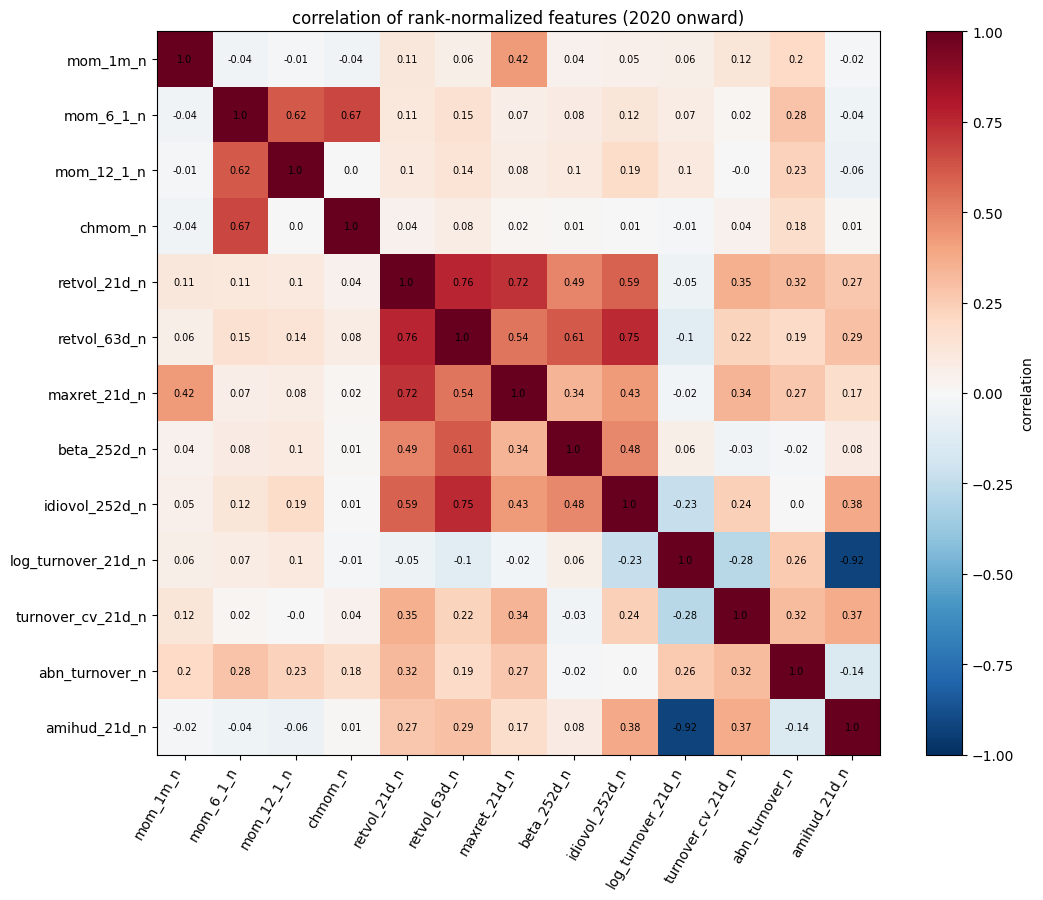

pairs with abs correlation > 0.8: 1
('log_turnover_21d_n', 'amihud_21d_n', np.float64(-0.924))
PASS: 8. correlation matrix computed with no nans, high pairs listed


In [24]:
# warm-up rows are all filled with 0, so leave them out or they would distort the correlations
not_warmup = saved_model_table[saved_model_table["split"] != "warmup"]
n_corr = not_warmup[n_columns].corr()

plt.figure(figsize=(11, 9))
plt.imshow(n_corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="correlation")
plt.xticks(range(len(n_columns)), n_columns, rotation=60, ha="right")
plt.yticks(range(len(n_columns)), n_columns)
for row in range(len(n_columns)):
    for col in range(len(n_columns)):
        plt.text(col, row, round(n_corr.iloc[row, col], 2), ha="center", va="center", fontsize=7)
plt.title("correlation of rank-normalized features (2020 onward)")
plt.tight_layout()
plt.show()

# list every pair above 0.8 (upper triangle only so each pair appears once)
high_pairs = []
for row in range(len(n_columns)):
    for col in range(row + 1, len(n_columns)):
        value = n_corr.iloc[row, col]
        if abs(value) > 0.8:
            high_pairs.append((n_columns[row], n_columns[col], round(value, 3)))

print("pairs with abs correlation > 0.8:", len(high_pairs))
for pair in high_pairs:
    print(pair)

report_check("8. correlation matrix computed with no nans, high pairs listed",
             n_corr.shape == (len(n_columns), len(n_columns)) and n_corr.notna().all().all())

### Check 9: last date with a 1-month label

In [25]:
labelled_rows = saved_model_table[saved_model_table["has_label_1m"]]
last_labelled_date = labelled_rows["Date"].max()
unlabelled_rows = saved_model_table[~saved_model_table["has_label_1m"]]

print("last Date with has_label_1m == True:", last_labelled_date.date())
print("rows without a 1m label:", len(unlabelled_rows), "on dates:", sorted(unlabelled_rows["Date"].dt.date.unique()))
report_check("9. last labelled date is end of july 2026", last_labelled_date == pd.Timestamp("2026-07-31"))

last Date with has_label_1m == True: 2026-07-31
rows without a 1m label: 30 on dates: [datetime.date(2026, 8, 31)]
PASS: 9. last labelled date is end of july 2026


## Summary

In [26]:
print("FEATURES BUILT")
print("day 3 momentum:   mom_1m, mom_6_1, mom_12_1, chmom")
print("day 3 volatility: retvol_21d, retvol_63d, maxret_21d, beta_252d, idiovol_252d")
print("day 4 liquidity:  ", liquidity_names)
print("sector-relative:  ", secrel_columns)
print("state variables:  ", state_names)
print("normalized stock columns (_n):", len(n_columns))
print()

print("CHECK RESULTS")
for name in check_results:
    if check_results[name]:
        print("PASS:", name)
    else:
        print("FAIL:", name)
print("all checks passed:", all(check_results.values()))
print()

print("ROWS PER SPLIT")
rows_per_split = saved_model_table.groupby("split").size()
for split_name in split_order:
    print(split_name, rows_per_split[split_name])
print("total:", len(saved_model_table))

FEATURES BUILT
day 3 momentum:   mom_1m, mom_6_1, mom_12_1, chmom
day 3 volatility: retvol_21d, retvol_63d, maxret_21d, beta_252d, idiovol_252d
day 4 liquidity:   ['log_turnover_21d', 'turnover_cv_21d', 'abn_turnover', 'amihud_21d']
sector-relative:   ['mom_12_1_secrel', 'retvol_63d_secrel', 'abn_turnover_secrel', 'amihud_21d_secrel']
state variables:   ['mkt_ret_1m', 'mkt_ret_12m', 'mkt_vol_63d', 'xs_dispersion', 'mkt_ret_1m_z', 'mkt_ret_12m_z', 'mkt_vol_63d_z', 'xs_dispersion_z']
normalized stock columns (_n): 13

CHECK RESULTS
PASS: 1. leakage test (uniform x1.5): all features on dates <= 2023-06-30 unchanged
PASS: 1b. leakage test (x1.5 on even days): all features on dates <= 2023-06-30 unchanged
PASS: 1c. the two tests together are sensitive: every feature changes after the cutoff
PASS: 1d. rebuilt features match the features used in the model table
PASS: 2. all _n and _secrel columns within [-1, 1], no nans
PASS: 3. every date has exactly 30 rows
PASS: 4. each state variable has 